In [ ]:
# Imports and data directory
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
from melon_pkg.plotting import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "05_Mouse_brain_five_modalities"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

OUTPUT = repo / "results/mouse_brain"
OUTPUT.mkdir(parents=True, exist_ok=True)


In [ ]:
# Multimodal inputs
import anndata as ad

modalities = ["RNA", "Protein", "ATAC", "H3K27ac", "H3K27me3"]
inputs = {
    modality: ad.read_h5ad(DATA / f"02_model_inputs/MELON/adata_{modality}.h5ad")
    for modality in modalities
}
barcodes = inputs["RNA"].obs_names
for adata in inputs.values():
    barcodes = barcodes.intersection(adata.obs_names, sort=False)
coords = pd.DataFrame(inputs["RNA"][barcodes].obsm["spatial"], index=barcodes, columns=["x", "y"])
features = [inputs[m][barcodes].to_df().to_numpy(dtype=np.float32) for m in modalities]
assert coords.index.is_unique and all(len(x) == len(coords) for x in features)
display(dict(zip(modalities, [x.shape for x in features])))


{'RNA': (9567, 30),
 'Protein': (9567, 30),
 'ATAC': (9567, 30),
 'H3K27ac': (9567, 30),
 'H3K27me3': (9567, 30)}

In [ ]:
# Parameters
config = {
    'epochs': 10,
    'batch_size': 2048,
    'embed_dim': 128,
    'training_seed': 2025,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 16,
    'export_spatial_k': 14,
    'augment_p': 1.0,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'clustering_seed': 2025,
    'clustering_neighbors': 15,
    'leiden_resolution': 0.70357421875,
    'clustering_pca_components': 20,
}


In [ ]:
# Spatial graph and augmented views
import torch
from torch import nn
from types import MethodType
import pytorch_lightning as pl
from melon_pkg.data import DualAugDataModule, SpatialOmicsAugmentations
from melon_pkg.model import SpotTokenAdapter
from melon_pkg.models.mmfusion import MMFusion
from melon_pkg.pl_modules.melon import MELONModel
from melon_pkg.utils import build_knn_mask
from melon_pkg.embedding import export_embedding

pl.seed_everything(config["training_seed"], workers=True)
tensors = [torch.tensor(x, dtype=torch.float32) for x in features]
xy = torch.as_tensor(coords.to_numpy(), dtype=torch.float32)
mask, weights = build_knn_mask(xy, k=config["training_spatial_k"],
                               include_self=True, return_weights=True, symmetric=True)
augmentation = SpatialOmicsAugmentations
aug = dict(augmentations=config["augmentations"], p=config["augment_p"], spatial_mix=True)
data = DualAugDataModule(
    mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weights,
    augmentA=augmentation(**aug), augmentB=augmentation(**aug),
    batch_size=config["batch_size"], shuffle=config["shuffle_batches"],
    spot_tokenization=True,
)


In [ ]:
# MELON model
dim = config["embed_dim"]
encoder = MMFusion(
    encoders=[nn.Sequential(nn.Linear(x.shape[1], dim), nn.ReLU(), nn.Linear(dim, dim))
              for x in tensors],
    input_adapters=[SpotTokenAdapter() for _ in tensors],
    embed_dim=dim, fusion="concat", pool="tokens", n_heads=8, n_layers=1,
)
model = MELONModel(
    encoder=encoder, projection=MELONModel._build_mlp(dim, 256, dim),
    optim_kwargs={"lr": config["learning_rate"], "weight_decay": config["weight_decay"]},
    loss_kwargs={"temperature": config["temperature"]},
    neighborhood_cfg={"hidden_dim": 64, "heads": 8, "dropout": 0.1,
                      "k_neighbors": config["training_spatial_k"], "include_self": True},
)
from melon_pkg.losses.melon_loss import SymmetricMELONLoss
model.loss = SymmetricMELONLoss(temperature=config["temperature"])


In [ ]:
# Train and embed
trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                     logger=False, enable_checkpointing=False, deterministic=True)
trainer.fit(model, datamodule=data)
embedding = pd.DataFrame(
    export_embedding(model, tensors, xy, spatial_k=config["export_spatial_k"]),
    index=coords.index,
)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})


{'spots': 9567, 'embedding_dimensions': 128}

In [ ]:
# Spatial clustering
import anndata as ad
import scanpy as sc
import igraph as ig
import leidenalg as la
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

clustering_features = normalize(PCA(
    n_components=config["clustering_pca_components"],
    random_state=config["clustering_seed"],
).fit_transform(embedding))
adata = ad.AnnData(clustering_features)
sc.pp.neighbors(adata, n_neighbors=config["clustering_neighbors"], use_rep="X",
                metric="euclidean", random_state=config["clustering_seed"])
edges = sparse.triu(adata.obsp["connectivities"], k=1).tocoo()
graph = ig.Graph(n=len(embedding), edges=list(zip(edges.row.tolist(), edges.col.tolist())),
                 directed=False)
partition = la.find_partition(
    graph, la.RBConfigurationVertexPartition, weights=edges.data.tolist(),
    resolution_parameter=config["leiden_resolution"],
    seed=config["clustering_seed"], n_iterations=-1,
)
domains = pd.Series(partition.membership, index=embedding.index, name="MELON")
display({"spatial_domains": domains.nunique()})


{'spatial_domains': 17}

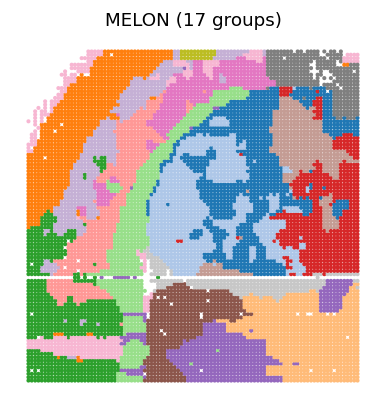

In [ ]:
# Spatial plot
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON_14_15"] = domains
palette = None
show(spatial_panels(plot_data, ["MELON_14_15"], colors=palette, ncols=1, point_size=6))


In [ ]:
# UMAP coordinates and colors
from umap import UMAP
from matplotlib import pyplot as plt
from matplotlib.colors import to_hex

umap_config = dict(n_neighbors=15, min_dist=0.3, metric="euclidean",
                   random_state=2025, n_jobs=1)
umap_xy = UMAP(**umap_config).fit_transform(clustering_features)
umap_coordinates = pd.DataFrame({
    "barcode": embedding.index, "method": "MELON_14_15",
    "cluster": domains.to_numpy(), "UMAP1": umap_xy[:, 0], "UMAP2": umap_xy[:, 1],
})
colors = {str(label): to_hex(plt.get_cmap("tab20")(int(label)))
          for label in sorted(domains.unique())}
umap_palette = pd.DataFrame({
    "method": "MELON_14_15", "cluster": list(colors), "color_hex": list(colors.values()),
})
umap_coordinates.to_csv(OUTPUT / "UMAP_coordinates.csv", index=False)
umap_palette.to_csv(OUTPUT / "cluster_palette.csv", index=False)


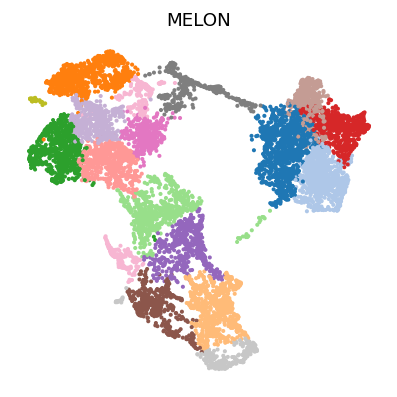

In [ ]:
# UMAP
umap_coordinates = pd.read_csv(OUTPUT / "UMAP_coordinates.csv", dtype={"barcode": str, "cluster": str})
umap_palette = saved_palette(OUTPUT / "cluster_palette.csv")
show(saved_umap_panels(umap_coordinates, umap_palette, ["MELON_14_15"]))
